In [2]:
import pandas as pd
from pathlib import Path

# Project root is the parent of the notebooks folder
PROJECT_ROOT = Path.cwd().parent

# Path to the original dataset
file_path = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"

# Check that the file exists
print("Dataset exists:", file_path.exists())

# Load the Excel file
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset exists: True
Dataset loaded successfully!


In [3]:
# First five rows
display(df.head())

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Dataset shape: (541909, 8)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
# Missing values in each column
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Basic statistics for numeric columns
display(df.describe())

# Negative quantities and prices
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())

Missing values:


CustomerID     135080
Description      1454
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64

Duplicate rows: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


Negative quantities: 10624
Negative unit prices: 2


In [5]:
print(df.shape)
print(df.isnull().sum())
print(df.duplicated().sum())

(541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
5268


In [6]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

file_path = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"

print("Dataset exists:", file_path.exists())

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset exists: True
Dataset loaded successfully!


In [7]:
# Inspect cancelled invoices
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled invoice rows:", len(cancelled))
display(cancelled.head())

# Inspect missing customer IDs
missing_customers = df[df["CustomerID"].isna()]

print("Rows with missing CustomerID:", len(missing_customers))
display(missing_customers.head())

# Inspect negative quantities
returns = df[df["Quantity"] < 0]

print("Negative quantity rows:", len(returns))
display(returns.head())

# Inspect negative prices
negative_prices = df[df["UnitPrice"] < 0]

print("Negative unit price rows:", len(negative_prices))
display(negative_prices)

Cancelled invoice rows: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Rows with missing CustomerID: 135080


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom


Negative quantity rows: 10624


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Negative unit price rows: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [8]:

import pandas as pd
from pathlib import Path

# Keep the original df unchanged
df_clean = df.copy()

# 1. Remove exact duplicate rows
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplicate rows removed:", before - len(df_clean))

# 2. Remove rows without essential transaction fields
before = len(df_clean)
df_clean = df_clean.dropna(
    subset=["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate"]
)
print("Rows missing essential fields removed:", before - len(df_clean))

# 3. Exclude cancelled invoices for the sales analysis
is_cancelled = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)
print("Cancelled invoice rows excluded:", is_cancelled.sum())
df_clean = df_clean.loc[~is_cancelled].copy()

# 4. Exclude zero or negative quantities and non-positive prices
# This creates a positive-sales dataset, not a returns analysis dataset.
before = len(df_clean)
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()
print("Rows with non-positive quantity/price removed:", before - len(df_clean))

# 5. Create a revenue column
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("\nOriginal rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing CustomerID remaining:", df_clean["CustomerID"].isna().sum())

display(df_clean.head())


Duplicate rows removed: 5268
Rows missing essential fields removed: 0
Cancelled invoice rows excluded: 9251
Rows with non-positive quantity/price removed: 2512

Original rows: 541909
Cleaned rows: 524878
Missing CustomerID remaining: 132186


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [9]:

PROJECT_ROOT = Path.cwd().parent
output_path = PROJECT_ROOT / "data" / "processed" / "sales_cleaned.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("File exists:", output_path.exists())


Cleaned dataset saved to: c:\Users\prais\share\doc\OneDrive\Desktop\sales-data-analysis\data\processed\sales_cleaned.csv
File exists: True


In [10]:

print("Rows:", len(df_clean))
print("Columns:", df_clean.shape[1])
print("Duplicate rows:", df_clean.duplicated().sum())
print("Invalid quantities:", (df_clean["Quantity"] <= 0).sum())
print("Invalid prices:", (df_clean["UnitPrice"] <= 0).sum())
print("Revenue missing:", df_clean["Revenue"].isna().sum())
print("Total positive sales value:", round(df_clean["Revenue"].sum(), 2))


Rows: 524878
Columns: 9
Duplicate rows: 0
Invalid quantities: 0
Invalid prices: 0
Revenue missing: 0
Total positive sales value: 10642110.8


In [11]:

import pandas as pd
from pathlib import Path

# Recreate the cleaned DataFrame
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows missing essential transaction fields
df_clean = df_clean.dropna(
    subset=["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate"]
)

# Exclude cancelled invoices
is_cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C")
df_clean = df_clean.loc[~is_cancelled].copy()

# Keep positive sales transactions
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Convert dates and calculate revenue
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Cleaning completed!")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))


Cleaning completed!
Original rows: 541909
Cleaned rows: 524878


In [12]:

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
file_path = PROJECT_ROOT / "data" / "processed" / "sales_cleaned.csv"

df_clean = pd.read_csv(file_path, parse_dates=["InvoiceDate"])

print("Dataset loaded:", df_clean.shape)
display(df_clean.head())


Dataset loaded: (524878, 9)


C:\Users\prais\AppData\Local\Temp\ipykernel_15032\157108978.py:9: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df_clean = pd.read_csv(file_path, parse_dates=["InvoiceDate"])


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [13]:

total_revenue = df_clean["Revenue"].sum()
total_units = df_clean["Quantity"].sum()
total_invoices = df_clean["InvoiceNo"].nunique()
unique_products = df_clean["StockCode"].nunique()
unique_countries = df_clean["Country"].nunique()

print(f"Total positive sales value: {total_revenue:,.2f}")
print(f"Total units sold: {total_units:,}")
print(f"Unique invoices: {total_invoices:,}")
print(f"Unique products: {unique_products:,}")
print(f"Countries represented: {unique_countries:,}")


Total positive sales value: 10,642,110.80
Total units sold: 5,572,420
Unique invoices: 19,962
Unique products: 3,922
Countries represented: 38


,Month,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


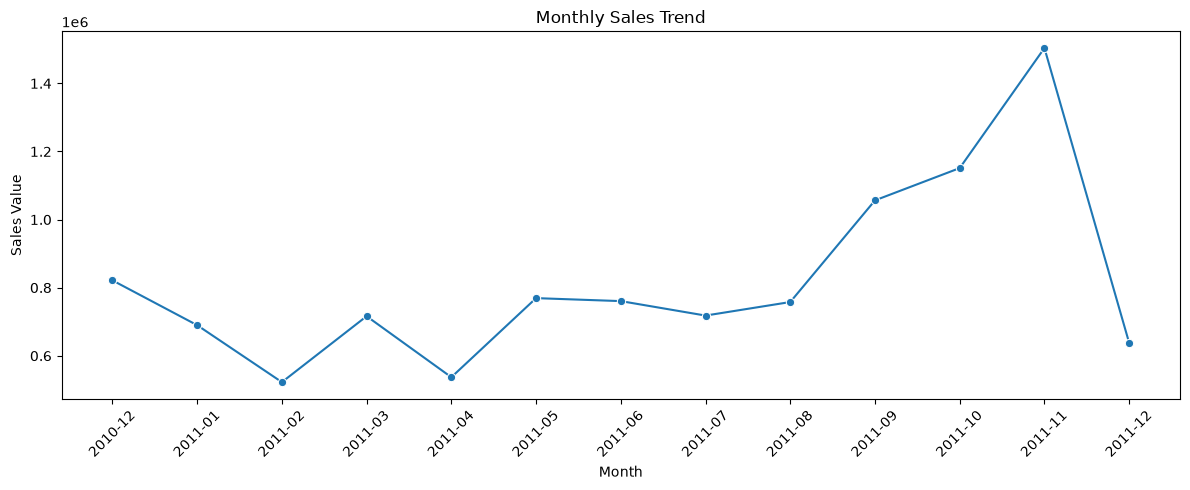

In [14]:

df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    df_clean.groupby("Month", as_index=False)["Revenue"]
    .sum()
    .sort_values("Month")
)

display(monthly_sales)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x="Month", y="Revenue", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Description,Revenue
1067,DOTCOM POSTAGE,206248.77
2853,REGENCY CAKESTAND 3 TIER,174156.54
2387,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3844,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
2413,PARTY BUNTING,99445.23
1816,JUMBO BAG RED RETROSPOT,94159.81
2052,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
2692,POSTAGE,78101.88
2192,Manual,77752.82
2741,RABBIT NIGHT LIGHT,66870.03


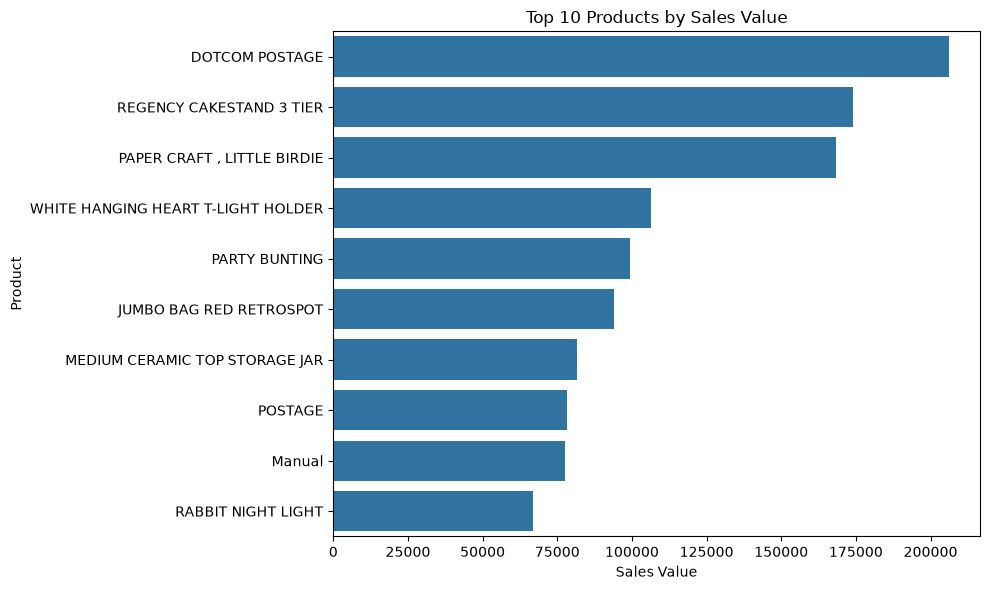

In [15]:

top_products = (
    df_clean.groupby("Description", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_products)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_products, x="Revenue", y="Description")
plt.title("Top 10 Products by Sales Value")
plt.xlabel("Sales Value")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


,Country,Revenue
36,United Kingdom,9001744.094
24,Netherlands,285446.340
10,EIRE,283140.520
14,Germany,228678.400
13,France,209625.370
0,Australia,138453.810
31,Spain,61558.560
33,Switzerland,57067.600
3,Belgium,41196.340
32,Sweden,38367.830


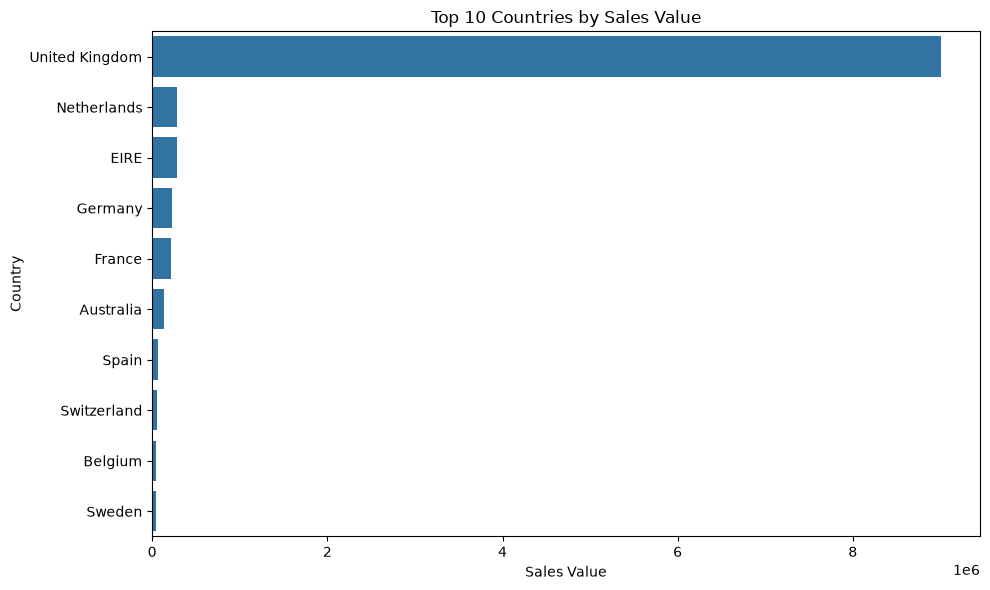

In [16]:

top_countries = (
    df_clean.groupby("Country", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_countries)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_countries, x="Revenue", y="Country")
plt.title("Top 10 Countries by Sales Value")
plt.xlabel("Sales Value")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [17]:

import sqlite3
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

csv_path = PROJECT_ROOT / "data" / "processed" / "sales_cleaned.csv"
db_path = PROJECT_ROOT / "data" / "processed" / "sales_analysis.db"

df_clean = pd.read_csv(csv_path, parse_dates=["InvoiceDate"])

# Store the cleaned data in a local SQLite database
with sqlite3.connect(db_path) as conn:
    df_clean.to_sql("sales", conn, if_exists="replace", index=False)

print("Database created:", db_path.exists())
print("Table created: sales")


C:\Users\prais\AppData\Local\Temp\ipykernel_15032\3665231500.py:9: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df_clean = pd.read_csv(csv_path, parse_dates=["InvoiceDate"])


Database created: True
Table created: sales


In [ ]:

import sqlite3
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
db_path = PROJECT_ROOT / "data" / "processed" / "sales_analysis.db"

with sqlite3.connect(db_path) as conn:
    result = pd.read_sql_query("""
        SELECT
            Country,
            ROUND(SUM(Revenue), 2) AS total_salegit statuss_value
        FROM sales
        GROUP BY Country
        ORDER BY total_sales_value DESC
        LIMIT 10;
    """, conn)

display(result)


,Country,total_sales_value
0,United Kingdom,9001744.09
1,Netherlands,285446.34
2,EIRE,283140.52
3,Germany,228678.40
4,France,209625.37
5,Australia,138453.81
6,Spain,61558.56
7,Switzerland,57067.60
8,Belgium,41196.34
9,Sweden,38367.83
